# Moment reproduction per statistic

For each statistic $k$, with $m_k$ = mean on the data x1 ($n$ windows) and $\hat m_k$ = mean on the model samples ($n_s$):

- **offset** $=\sqrt{e_k} = |m_k-\hat m_k| / \mathrm{std}_{data,k}$: how far the model's mean is, in standard deviations of the data (not a % of the mean). Reading: < 0.05 very good, 0.05–0.2 small shift, 0.2–0.5 clear shift, > 0.5 big miss.
- **noise** $=\sqrt{(s^2_{data}/n + s^2_{model}/n_s)}/\mathrm{std}_{data}$: the offset expected from finite samples alone (≈ 0.014 at $n=n_s=10^4$ for well-behaved statistics, much larger for heavy-tailed ones).
- **Verdict** of each statistic (heatmap):
  - **grey = matched**: offset ≤ 2 × noise, and 2 × noise < 0.05, so the measurement is sharp enough to call it a match;
  - **hatched = can't tell**: offset ≤ 2 × noise, but the noise is too large to judge;
  - **colour = miss**: the offset, fixed log scale 0.01 to 1.
- **rel_mean** $=(\hat m_k-m_k)/|m_k|$: percentage error, in the table only, where the mean is clearly away from 0.

Imposed (dot) = the run's own potentials (config.json + fitted_potentials/, never refitted). Extra = chosen in the ⚠ cell. First seed of each label. Run on Jean Zay. Models are grouped by dataset: rows of one heatmap share M, J, Q. Thresholds: `NOISE_K`, `RESOLVED_MAX`, `REL_MEAN_MIN`, `OFFSET_RANGE` at the top of `moment_reproduction.py`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'moment_reproduction'))
import numpy as np
from moment_reproduction import load_model, compute_moment_reproduction, plot_summary, plot_strip, DEVICE
%matplotlib inline

In [2]:
# ── MODELS ── group -> {row name: (results root, --label of the run)}. Every statistic a model imposes
# is always checked (loaded with its saved fit, never refitted).
# Turbulence rows: mass_final = M3 + Scat4; M3 = unconstrained windows; A = windows >= step noise;
# B = A + mass of every window. GGD columns are aligned by (channel, window) label, but M3/mass_final
# windows differ from A/B windows: same label != same window across those two pairs.
GROUPS = {
    # 'turbulence (M=256, J=8, Q=3)': {
    #     #'full (Scat4)':      (ROOT / 'turbulence', 'turbulence_ggd_mass_final'),
    #     #'M3':                (ROOT / 'turbulence', 'turbulence_nested_M3'),
    #     #'A (bicw)':          (ROOT / 'turbulence', 'turbulence_nested_M3_bicw'),
    #     #'B (bicw_allmass)':  (ROOT / 'turbulence', 'turbulence_nested_M3_bicw_allmass'),
    #     'C (bicw_rich)':     (ROOT / 'turbulence', 'turbulence_nested_M3_bicw_rich'),
    #     'B + Scat4':         (ROOT / 'turbulence', 'turbulence_nested_M3_bicw_allmass_scat4'),
    # },
    'jets (M=256, J=8, Q=1)': {
        'jets full':                  (ROOT / 'jets', 'jets_full'),
        'no scalar':                  (ROOT / 'jets', 'jets_noscalar'),
        'no Scat3/4':                 (ROOT / 'jets', 'jets_scat2_scalar'),
        'no Scat3/4, no scalar':      (ROOT / 'jets', 'jets_scat2'),
    },
}

## ⚠ CHOOSE THE EXTRA STATISTICS HERE

The **imposed** statistics of each model are always checked, with no choice needed. `EXTRA` lists the **additional, non-imposed** families evaluated on every model of a group. A family that a model imposes stays imposed for that model, using its own fit (matched by family name). The same extra family is a *test* for the models that don't impose it.

- Scattering / L_p extras: no fit, same definition for every model.
- `Scalar_*` extras (GGD): windows **fitted once on the data x1** (final-model settings, `EXTRA_GGD` in `moment_reproduction.py`), saved in `moment_reproduction/cache/`, and reused for every model with the same x1.
- Not caught automatically: two families with different names computing the same numbers. For example, with Q=1 (jets) `Scalar_psi` runs on the same bank as `Scalar_morlet`.

In [3]:
# ── EXTRA (non-imposed) STATISTICS ── edit this list only; one per line, with why it is here.
EXTRA = [
    'L_6',                                      # 6th-order marginal moment (imposed by most turbulence models)
    'Scattering_First_Order',                   # E|W x| per channel
    'Scattering_Second_Order',                  # E|W |W x||: scale-to-scale envelope
    'Scattering_Third_Order_Real',              # cross-scale phase (Q=3 bank, as the code does)
    'Scattering_Third_Order_Imag',
    'Scattering_Fourth_Order_Mod2_Real_Q1',     # the Scat4 mass_final IMPOSES: test for M3 / A / B
    'Scattering_Fourth_Order_Mod2_Imag_Q1',
    'Scalar_morlet_gaussianK',                  # marginals Q=1 bank (imposed by all turbulence models)
    'Scalar_psi_gaussianK',                     # marginals Q=3 bank (imposed by all turbulence models)
    'Scalar_morlet_gaussianK_imag',             # marginals of the imaginary parts: fitted here (not imposed)
    'Scalar_psi_gaussianK_imag',
    'Scalar_Q4_gaussianK',                      # marginals, Q=4 bank at the run's J=8
    'Scalar_Q5_gaussianK',                      # marginals, Q=5 bank
]
print(f'device: {DEVICE}')

device: cuda


In [4]:
import time
results, excluded = {}, {}
for group, models in GROUPS.items():
    results[group], shapes = {}, set()
    for name, (root, label) in models.items():
        t0 = time.time()
        cfg, pots, x1, xs = load_model(label, root)
        shapes.add((cfg['M'], cfg['J'], cfg['Q']))
        extra = [f for f in EXTRA if f not in pots]
        print(f'\n{name}: {cfg["config_name"]}  n={len(x1)} n_s={len(xs)}\n  imposed: {list(pots)}\n  extra:   {extra}')
        results[group][name], excluded[name] = compute_moment_reproduction(pots, x1, xs, EXTRA, cfg)
        print(f'  excluded (zero variance on data): {list(excluded[name].label)}  ({time.time() - t0:.0f} s)')
    assert len(shapes) == 1, f'{group}: models with different (M, J, Q) {shapes}: split the group'

[deduplicate_filters] filters_Q: 9 -> 9 channels for channel-list potentials (dropped duplicates [], tol=1e-08)

jets full: jetsynth_modane_M256_J8_Q1_sigma3.5_nt40000_n1_10000_lam0.0_spread_thomas_nsub1_moment_f64_dedupfilt1e-08_seed_500_terms939b4857_jets_full_20261028_1405  n=10000 n_s=10000
  imposed: ['L_6', 'Scalar_morlet_gaussianK', 'Scattering_First_Order', 'Scattering_Second_Order', 'Scattering_Third_Order_Real', 'Scattering_Third_Order_Imag', 'Scattering_Fourth_Order_Mod2_Real_Q1', 'Scattering_Fourth_Order_Mod2_Imag_Q1']
  extra:   ['Scalar_psi_gaussianK', 'Scalar_morlet_gaussianK_imag', 'Scalar_psi_gaussianK_imag', 'Scalar_Q4_gaussianK', 'Scalar_Q5_gaussianK']
[deduplicate_filters] filters_Q: 9 -> 9 channels for channel-list potentials (dropped duplicates [], tol=1e-08)
[extra] Scalar_psi_gaussianK: windows loaded from Scalar_psi_gaussianK_32ae56403f935338.pt
[deduplicate_filters] filters_Q: 9 -> 9 channels for channel-list potentials (dropped duplicates [], tol=1e-08)
[extr

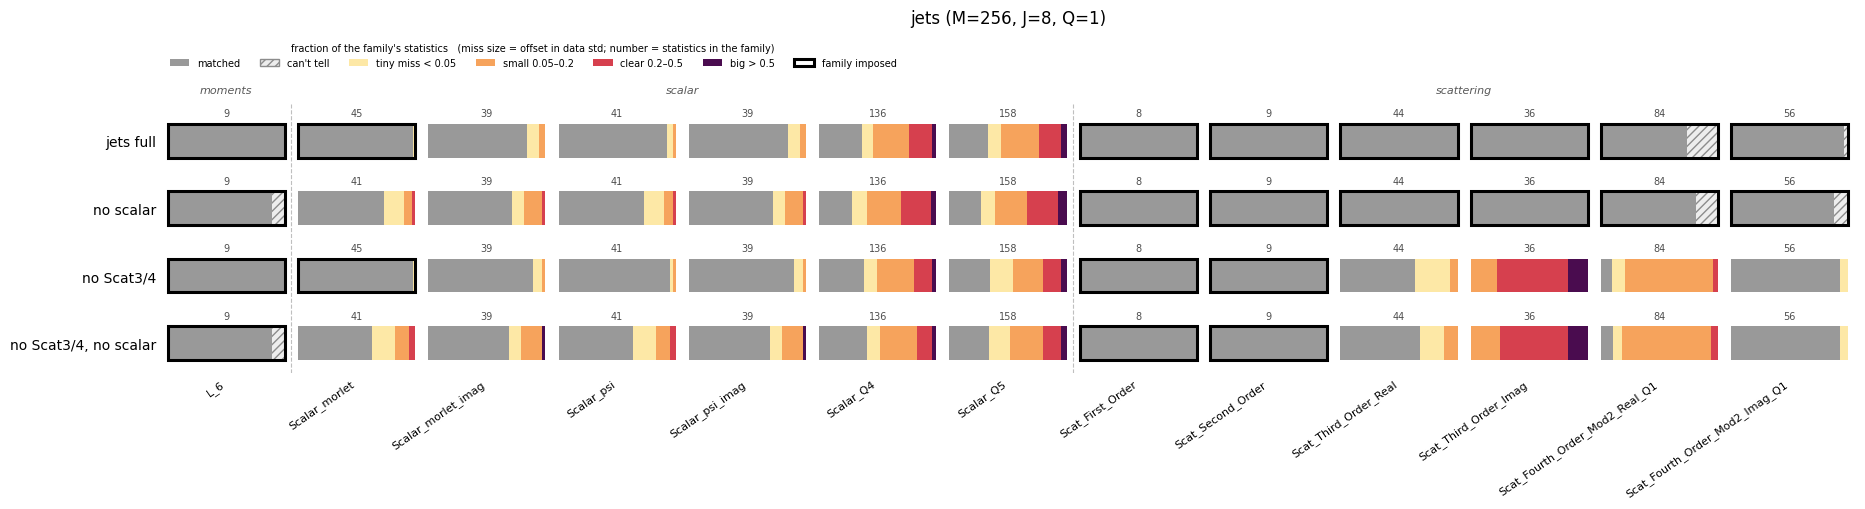

In [5]:
# Overview: one cell per (model, family) = fraction of that family's statistics matched / can't tell /
# missed by size. Thick frame = family imposed by the model. Details per statistic: strip plots below.
for group, res in results.items():
    plot_summary(res, title=group)

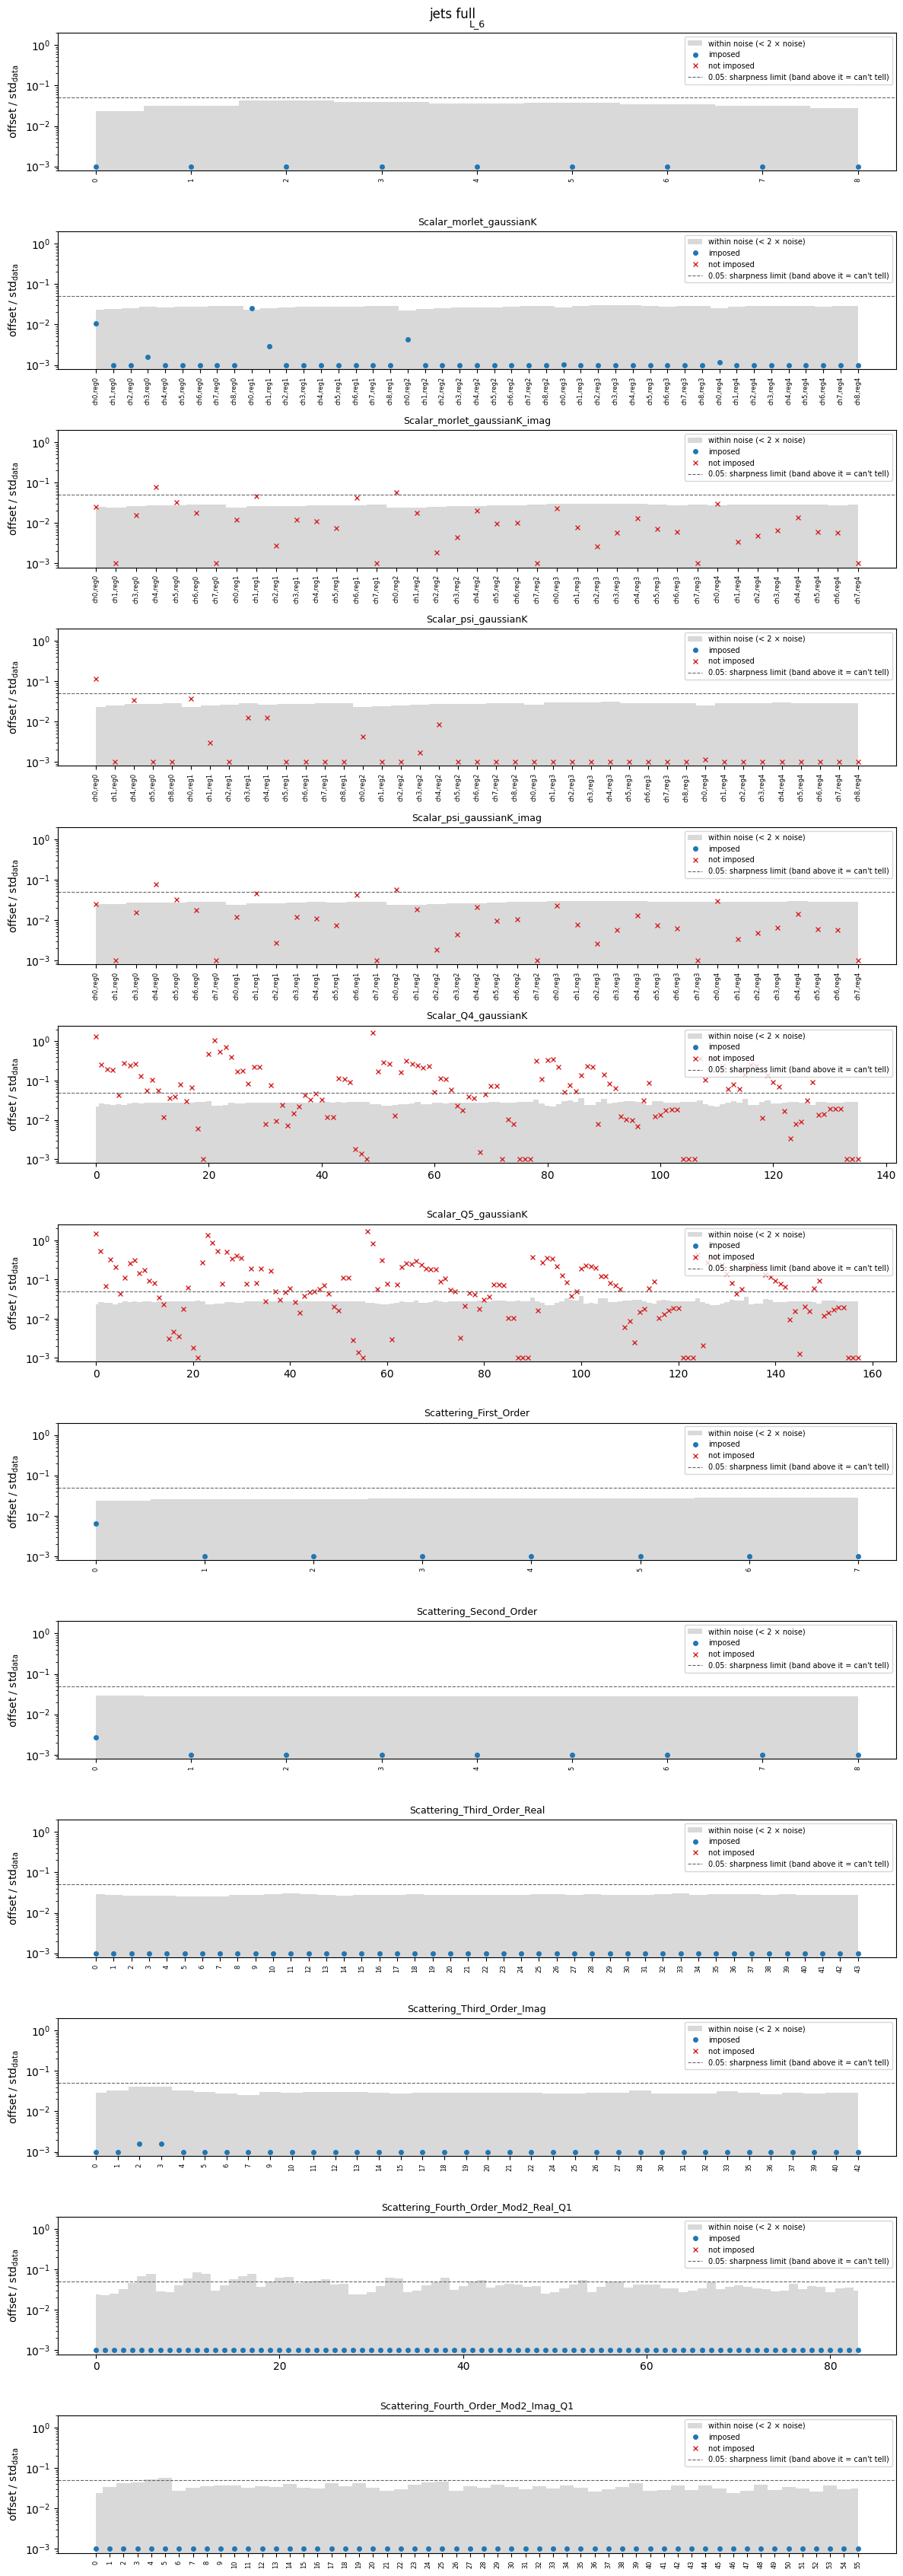

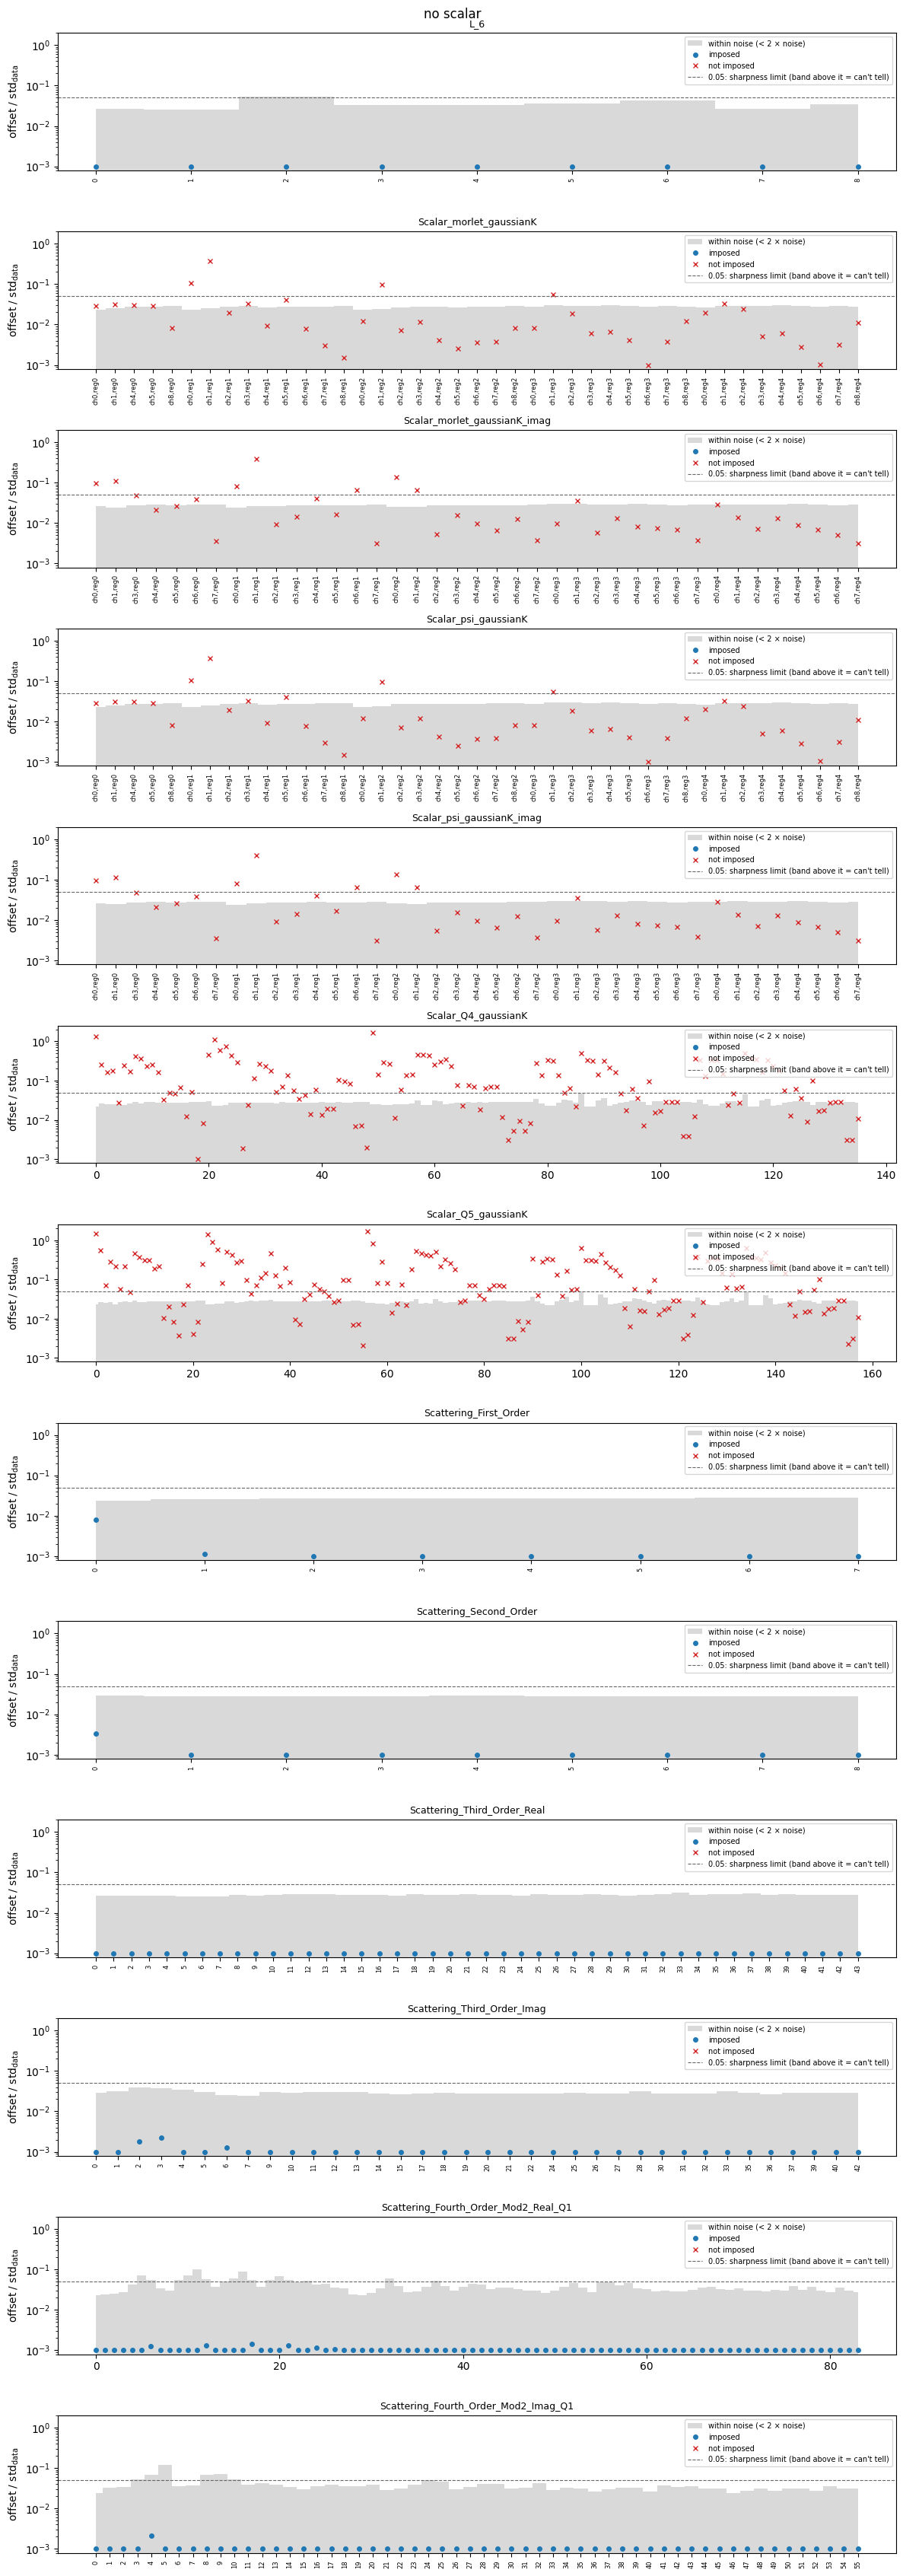

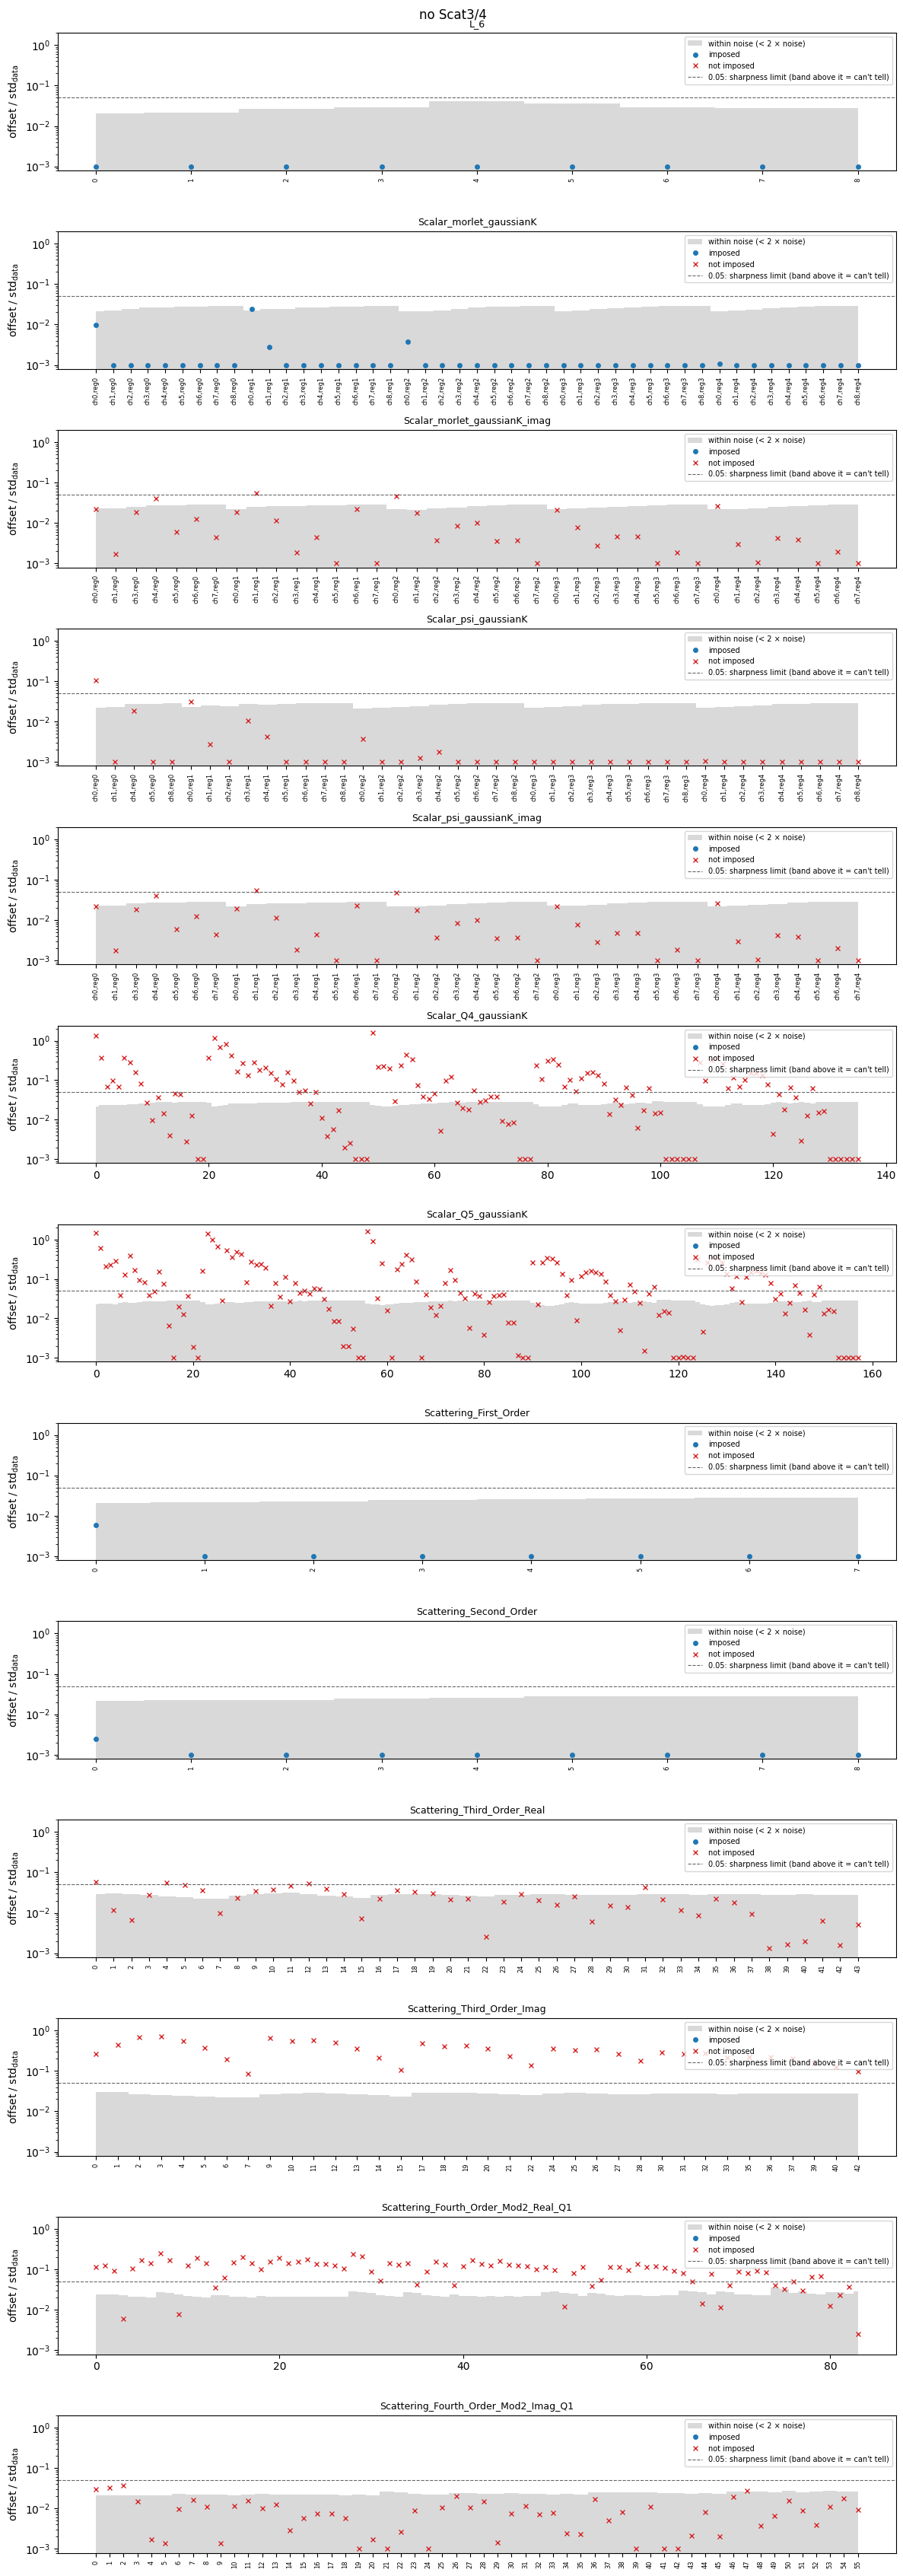

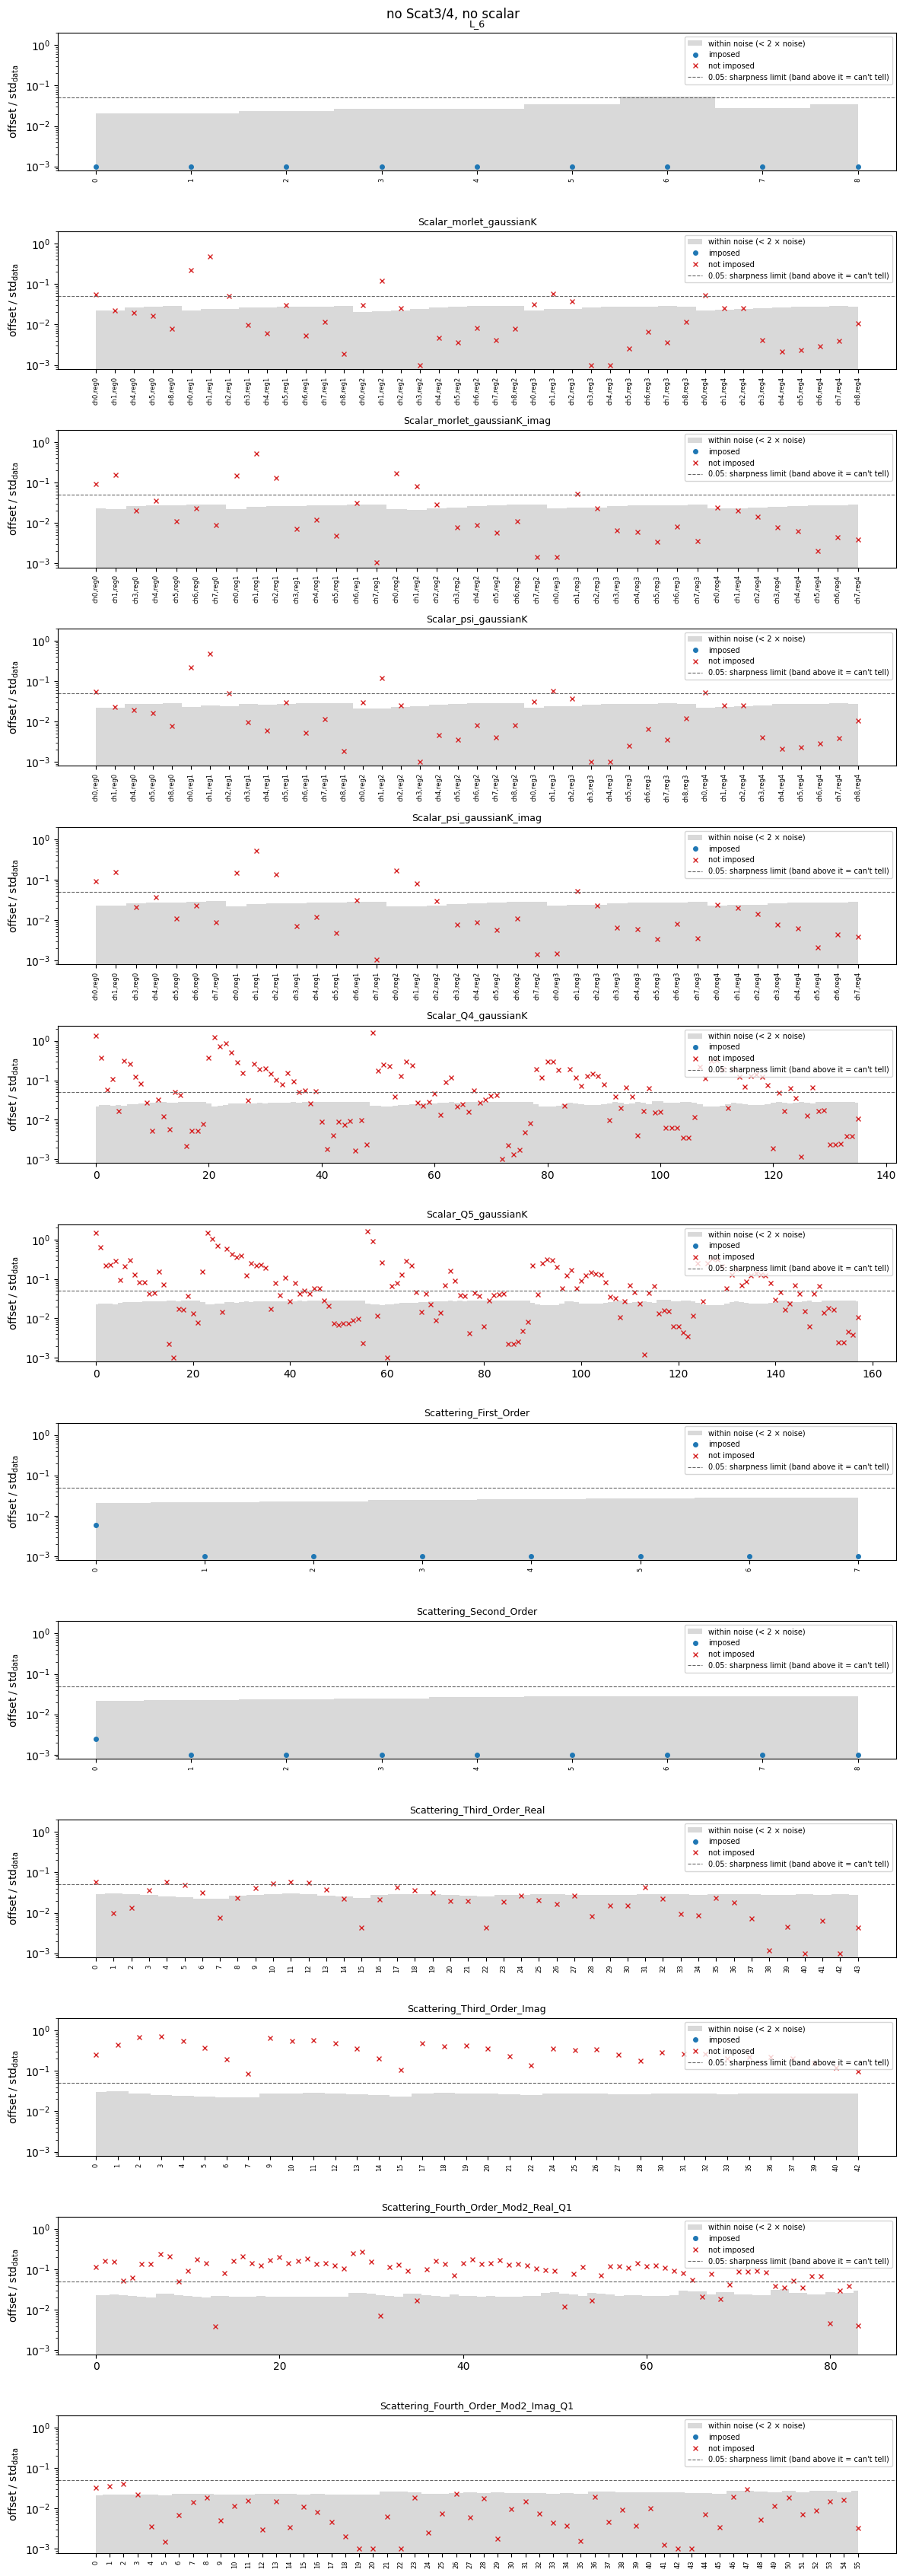

In [6]:
for group, res in results.items():
    for name, df in res.items():
        plot_strip(df).suptitle(name, y=1.0)

In [7]:
# Table per model and family. offset = |m - mhat| / std_data. Verdict per statistic:
#   matched = within 2 x noise AND 2 x noise < 0.05 (sharp);  can't tell = within noise but noise too large;
#   miss = outside noise.  rel_mean = (mhat - m)/|m| in %, only where |m| >= 0.5 std_data (else blank).
import pandas as pd
pd.set_option('display.float_format', '{:.3g}'.format)
for group, res in results.items():
    for name, df in res.items():
        print(f'\n== {name}')
        g = df.groupby(['imposed', 'family'])
        display(pd.DataFrame({
            'n':                   g.size(),
            'matched %':           100 * g['verdict'].apply(lambda s: (s == 'matched').mean()),
            "can't tell %":        100 * g['verdict'].apply(lambda s: (s == 'unresolved').mean()),
            'miss %':              100 * g['verdict'].apply(lambda s: (s == 'miss').mean()),
            'offset median':       g['offset'].median(),
            'offset max':          g['offset'].max(),
            '|rel_mean| median %': 100 * g['rel_mean'].apply(lambda s: s.abs().median()),
            'rel_mean shown':      g['rel_mean'].count(),
        }))
        big = df[df.offset > 0.1].sort_values('offset', ascending=False)
        print(f'offset > 0.1 std_data: {len(big)} statistics (top 30)')
        display(big[['family', 'label', 'imposed', 'verdict', 'offset', 'noise', 'rel_mean']].head(30))


== jets full


n  matched %  can't tell %  \
imposed family                                                               
False   Scalar_Q4_gaussianK                   136       36.8             0   
        Scalar_Q5_gaussianK                   158       32.9             0   
        Scalar_morlet_gaussianK_imag           39       84.6             0   
        Scalar_psi_gaussianK                   41       92.7             0   
        Scalar_psi_gaussianK_imag              39       84.6             0   
True    L_6                                     9        100             0   
        Scalar_morlet_gaussianK                45       97.8             0   
        Scattering_First_Order                  8        100             0   
        Scattering_Fourth_Order_Mod2_Imag_Q1   56       96.4          3.57   
        Scattering_Fourth_Order_Mod2_Real_Q1   84       73.8          26.2   
        Scattering_Second_Order                 9        100             0   
        Scattering_Third_Order_Imag            36        100             0   
        Scattering_Third_Order_Real            44        100             0   

                                              miss %  offset median  \
imposed family                                                        
False   Scalar_Q4_gaussianK                     63.2          0.058   
        Scalar_Q5_gaussianK                     67.1         0.0657   
        Scalar_morlet_gaussianK_imag            15.4        0.00772   
        Scalar_psi_gaussianK                    7.32       4.42e-05   
        Scalar_psi_gaussianK_imag               15.4        0.00772   
True    L_6                                        0       9.79e-06   
        Scalar_morlet_gaussianK                 2.22       3.06e-05   
        Scattering_First_Order                     0       2.84e-05   
        Scattering_Fourth_Order_Mod2_Imag_Q1       0       8.18e-05   
        Scattering_Fourth_Order_Mod2_Real_Q1       0       3.45e-05   
        Scattering_Second_Order                    0       6.91e-06   
        Scattering_Third_Order_Imag                0        7.2e-05   
        Scattering_Third_Order_Real                0       4.08e-05   

                                              offset max  |rel_mean| median %  \
imposed family                                                                  
False   Scalar_Q4_gaussianK                         1.67                 4.44   
        Scalar_Q5_gaussianK                         1.72                 4.88   
        Scalar_morlet_gaussianK_imag               0.077                0.638   
        Scalar_psi_gaussianK                       0.113               0.0137   
        Scalar_psi_gaussianK_imag                  0.077                0.638   
True    L_6                                     4.96e-05                  NaN   
        Scalar_morlet_gaussianK                   0.0256              0.00188   
        Scattering_First_Order                   0.00647             0.000931   
        Scattering_Fourth_Order_Mod2_Imag_Q1    0.000707                  NaN   
        Scattering_Fourth_Order_Mod2_Real_Q1     0.00101               0.0139   
        Scattering_Second_Order                  0.00273              0.00085   
        Scattering_Third_Order_Imag              0.00157               0.0703   
        Scattering_Third_Order_Real             0.000435                  NaN   

                                              rel_mean shown  
imposed family                                                
False   Scalar_Q4_gaussianK                               99  
        Scalar_Q5_gaussianK                              108  
        Scalar_morlet_gaussianK_imag                      34  
        Scalar_psi_gaussianK                              33  
        Scalar_psi_gaussianK_imag                         34  
True    L_6                                                0  
        Scalar_morlet_gaussianK                           37  
        Scattering_First_Ord

offset > 0.1 std_data: 109 statistics (top 30)


,family,label,imposed,verdict,offset,noise,rel_mean
602,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch0,reg2]",False,miss,1.72,0.0127,0.951
459,Scalar_Q4_gaussianK,"Scalar_Q4_gaussianK[ch0,reg2]",False,miss,1.67,0.0128,0.971
546,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch0,reg0]",False,miss,1.5,0.0117,-0.41
569,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch1,reg1]",False,miss,1.36,0.0114,0.415
410,Scalar_Q4_gaussianK,"Scalar_Q4_gaussianK[ch0,reg0]",False,miss,1.32,0.0108,-0.527
431,Scalar_Q4_gaussianK,"Scalar_Q4_gaussianK[ch1,reg1]",False,miss,1.07,0.0114,0.436
570,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch2,reg1]",False,miss,0.873,0.0116,0.275
603,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch1,reg2]",False,miss,0.841,0.0125,0.603
433,Scalar_Q4_gaussianK,"Scalar_Q4_gaussianK[ch3,reg1]",False,miss,0.723,0.0121,0.157
432,Scalar_Q4_gaussianK,"Scalar_Q4_gaussianK[ch2,reg1]",False,miss,0.551,0.0116,0.179



== no scalar


n  matched %  can't tell %  \
imposed family                                                               
False   Scalar_Q4_gaussianK                   136       27.9             0   
        Scalar_Q5_gaussianK                   158       27.2             0   
        Scalar_morlet_gaussianK                41       73.2             0   
        Scalar_morlet_gaussianK_imag           39       71.8             0   
        Scalar_psi_gaussianK                   41       73.2             0   
        Scalar_psi_gaussianK_imag              39       71.8             0   
True    L_6                                     9       88.9          11.1   
        Scattering_First_Order                  8        100             0   
        Scattering_Fourth_Order_Mod2_Imag_Q1   56       87.5          12.5   
        Scattering_Fourth_Order_Mod2_Real_Q1   84         81            19   
        Scattering_Second_Order                 9        100             0   
        Scattering_Third_Order_Imag            36        100             0   
        Scattering_Third_Order_Real            44        100             0   

                                              miss %  offset median  \
imposed family                                                        
False   Scalar_Q4_gaussianK                     72.1         0.0703   
        Scalar_Q5_gaussianK                     72.8         0.0709   
        Scalar_morlet_gaussianK                 26.8        0.00822   
        Scalar_morlet_gaussianK_imag            28.2          0.013   
        Scalar_psi_gaussianK                    26.8        0.00822   
        Scalar_psi_gaussianK_imag               28.2          0.013   
True    L_6                                        0        2.3e-05   
        Scattering_First_Order                     0       6.88e-05   
        Scattering_Fourth_Order_Mod2_Imag_Q1       0       7.52e-05   
        Scattering_Fourth_Order_Mod2_Real_Q1       0       5.59e-05   
        Scattering_Second_Order                    0       6.44e-05   
        Scattering_Third_Order_Imag                0       0.000114   
        Scattering_Third_Order_Real                0       4.48e-05   

                                              offset max  |rel_mean| median %  \
imposed family                                                                  
False   Scalar_Q4_gaussianK                         1.67                 6.14   
        Scalar_Q5_gaussianK                         1.71                 6.14   
        Scalar_morlet_gaussianK                    0.365                0.937   
        Scalar_morlet_gaussianK_imag               0.395                 1.34   
        Scalar_psi_gaussianK                       0.365                0.937   
        Scalar_psi_gaussianK_imag                  0.395                 1.34   
True    L_6                                     9.04e-05                  NaN   
        Scattering_First_Order                   0.00804              0.00302   
        Scattering_Fourth_Order_Mod2_Imag_Q1     0.00216                  NaN   
        Scattering_Fourth_Order_Mod2_Real_Q1     0.00146               0.0295   
        Scattering_Second_Order                   0.0034              0.00606   
        Scattering_Third_Order_Imag              0.00225               0.0425   
        Scattering_Third_Order_Real             0.000809                  NaN   

                                              rel_mean shown  
imposed family                                                
False   Scalar_Q4_gaussianK                               99  
        Scalar_Q5_gaussianK                              108  
        Scalar_morlet_gaussianK                           33  
        Scalar_morlet_gaussianK_imag                      34  
        Scalar_psi_gaussianK                              33  
        Scalar_psi_gaussianK_imag                         34  
True    L_6                                                0  
        Scattering_First_Ord

... (6 outputs left out)


== no Scat3/4, no scalar


n  matched %  can't tell %  \
imposed family                                                               
False   Scalar_Q4_gaussianK                   136       41.2             0   
        Scalar_Q5_gaussianK                   158       33.5             0   
        Scalar_morlet_gaussianK                41       63.4             0   
        Scalar_morlet_gaussianK_imag           39       69.2             0   
        Scalar_psi_gaussianK                   41       63.4             0   
        Scalar_psi_gaussianK_imag              39       69.2             0   
        Scattering_Fourth_Order_Mod2_Imag_Q1   56       92.9             0   
        Scattering_Fourth_Order_Mod2_Real_Q1   84       10.7             0   
        Scattering_Third_Order_Imag            36          0             0   
        Scattering_Third_Order_Real            44       68.2             0   
True    L_6                                     9       88.9          11.1   
        Scattering_First_Order                  8        100             0   
        Scattering_Second_Order                 9        100             0   

                                              miss %  offset median  \
imposed family                                                        
False   Scalar_Q4_gaussianK                     58.8         0.0422   
        Scalar_Q5_gaussianK                     66.5         0.0466   
        Scalar_morlet_gaussianK                 36.6        0.00974   
        Scalar_morlet_gaussianK_imag            30.8         0.0109   
        Scalar_psi_gaussianK                    36.6        0.00974   
        Scalar_psi_gaussianK_imag               30.8         0.0109   
        Scattering_Fourth_Order_Mod2_Imag_Q1    7.14         0.0074   
        Scattering_Fourth_Order_Mod2_Real_Q1    89.3          0.112   
        Scattering_Third_Order_Imag              100          0.275   
        Scattering_Third_Order_Real             31.8         0.0204   
True    L_6                                        0       7.76e-06   
        Scattering_First_Order                     0       2.65e-05   
        Scattering_Second_Order                    0       8.66e-06   

                                              offset max  |rel_mean| median %  \
imposed family                                                                  
False   Scalar_Q4_gaussianK                         1.61                 3.81   
        Scalar_Q5_gaussianK                         1.64                 3.93   
        Scalar_morlet_gaussianK                    0.485                0.694   
        Scalar_morlet_gaussianK_imag               0.518                 1.05   
        Scalar_psi_gaussianK                       0.485                0.694   
        Scalar_psi_gaussianK_imag                  0.518                 1.05   
        Scattering_Fourth_Order_Mod2_Imag_Q1      0.0399                  NaN   
        Scattering_Fourth_Order_Mod2_Real_Q1       0.271                 19.7   
        Scattering_Third_Order_Imag                0.712                 97.2   
        Scattering_Third_Order_Real               0.0585                  NaN   
True    L_6                                     4.25e-05                  NaN   
        Scattering_First_Order                   0.00587             0.000871   
        Scattering_Second_Order                  0.00249             0.000968   

                                              rel_mean shown  
imposed family                                                
False   Scalar_Q4_gaussianK                               99  
        Scalar_Q5_gaussianK                              108  
        Scalar_morlet_gaussianK                           33  
        Scalar_morlet_gaussianK_imag                      34  
        Scalar_psi_gaussianK                              33  
        Scalar_psi_gaussianK_imag                         34  
        Scattering_Fourth_Order_Mod2_Imag_Q1               0  
        Scattering_Fourth_Or

offset > 0.1 std_data: 196 statistics (top 30)


,family,label,imposed,verdict,offset,noise,rel_mean
598,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch0,reg2]",False,miss,1.64,0.0116,0.905
455,Scalar_Q4_gaussianK,"Scalar_Q4_gaussianK[ch0,reg2]",False,miss,1.61,0.0115,0.936
542,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch0,reg0]",False,miss,1.47,0.0112,-0.4
565,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch1,reg1]",False,miss,1.46,0.0112,0.447
406,Scalar_Q4_gaussianK,"Scalar_Q4_gaussianK[ch0,reg0]",False,miss,1.32,0.0106,-0.527
427,Scalar_Q4_gaussianK,"Scalar_Q4_gaussianK[ch1,reg1]",False,miss,1.22,0.0109,0.495
566,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch2,reg1]",False,miss,1.05,0.0112,0.33
599,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch1,reg2]",False,miss,0.899,0.0113,0.645
429,Scalar_Q4_gaussianK,"Scalar_Q4_gaussianK[ch3,reg1]",False,miss,0.852,0.0119,0.185
428,Scalar_Q4_gaussianK,"Scalar_Q4_gaussianK[ch2,reg1]",False,miss,0.733,0.0112,0.238


## Moment reproduction vs contribution to −log p, per category
The talk's energy table (same categories and layout), one block per model, with the moment reproduction added. Columns: scalar multiscale (marginals + scattering 1–2) · scalar Im (marginals of the imaginary parts) · order 3 Re / Im · order 4 Re / Im · confinement ($L_6$). Only the families the model **imposes** count (they are the ones with a $\Theta$).
Rows: number of moments · **moments matched** (% of those statistics with a 'matched' verdict) · **mean offset** (mean over those statistics, in data std) · mean and std over the data signals of the category's contribution to $-\log p$ (sum of its families' contributions, std of the sum; variance = std²; the mean is a level only).
−log p comes from `turbulence/figures/data/logp_C_<label>_lam*.npz` (the L$_6<0$ file when there is one) or `jets/figures/logp_jets/logp_jets.npz` (printed below); a model with no such file shows '—' for $-\log p$. Seed = that of the moment-reproduction run, so no ± over seeds. Saved in `moment_reproduction/figures/`.

In [ ]:
from moment_reproduction import load_logp_contributions, plot_moment_vs_logp
from codes import talk_figures as tf
tf.set_output(ROOT / 'moment_reproduction' / 'figures')
for group, res in results.items():
    logp = {}
    for name in res:
        root, label = GROUPS[group][name]
        logp[name], src = load_logp_contributions(label, root)
        print(f'{name}: ' + (src if logp[name] is not None else f'NO log p ({src})'))
    plot_moment_vs_logp(res, logp, 'moment_vs_logp_' + group.split(' ')[0])